# 🛡️ Air Raid Alert Time Series Forecasting: Comprehensive Evaluation & Regional Dashboards

This notebook performs:
1. **Multi-Horizon Out-of-Time Evaluation** (Tactical 1h, Operational 4h, Strategic 24h)
2. **Benchmark against 3 Naive Baselines**:
   - **Persistence Baseline** (current active state)
   - **Regional Climatology Baseline** (historical base rate per region)
   - **Spatial Neighbor Heuristic** (active neighbor pressure)
3. **Defense-Centric Metrics**: PR-AUC, ROC-AUC, Brier Score, and $F_2$-Score (prioritizing recall for safety)
4. **Per-Region Accuracy & $F_2$ Color Heatmap Dashboard** across all 25 Ukrainian administrative entities
5. **Interactive Geographic Map of Ukraine** rendering forecasting accuracy and risk lift by region.


In [5]:
import sys
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium

# Style configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 11

from src.geo_graph import REGIONS, REGION_TO_IDX, ADJACENCY_MATRIX
from src.grid_builder import load_raw_alerts, build_hourly_alert_grid
from src.features import compute_spatio_temporal_features
from src.evaluate import evaluate_predictions, compute_naive_baselines, compute_regional_breakdown
from src.models import FEATURE_COLUMNS, train_and_evaluate_horizon

print("Modules imported successfully!")


Modules imported successfully!


In [6]:
# Load alerts and build regular point-in-time features
df_alerts = load_raw_alerts('official_data_en.csv', start_date='2024-01-01')
df_grid = build_hourly_alert_grid(df_alerts, freq='1h')
df_features, targets = compute_spatio_temporal_features(df_grid)

# Strict Out-of-Time Temporal Split (Latest 45 days as holdout test)
max_time = df_features['timestamp'].max()
test_cutoff = max_time - pd.Timedelta(days=45)

train_mask = df_features['timestamp'] < test_cutoff
test_mask = df_features['timestamp'] >= test_cutoff

df_train = df_features[train_mask].copy()
df_test = df_features[test_mask].copy()

print("Train observations:", len(df_train))
print("Holdout Test observations:", len(df_test))


Loading raw alerts from official_data_en.csv...
Loaded 229,581 valid alert intervals across 24 regions.
Building hourly grid from 2023-12-31 14:00:00+00:00 to 2026-09-07 06:00:00+00:00 (23,537 time steps)...
Grid built successfully. Overall alert prevalence: 34.9936%
Computing spatio-temporal features and multi-horizon targets...
Features created successfully: 583,625 sample rows.
Train observations: 556600
Holdout Test observations: 27025


In [7]:
horizons = [('1h', 'target_1h'), ('4h', 'target_4h'), ('24h', 'target_24h')]
benchmark_rows = []
regional_dfs = {}
trained_models = {}

for h_name, target_col in horizons:
    # 1. Train LightGBM model
    res = train_and_evaluate_horizon(df_train, df_test, target_col, h_name)
    model = res['model']
    trained_models[h_name] = model
    y_test = df_test[target_col].values
    y_prob = model.predict_proba(df_test[FEATURE_COLUMNS])[:, 1]
    
    # 2. Compute Model Metrics
    m_metrics = evaluate_predictions(y_test, y_prob)
    
    # 3. Compute Naive Baselines
    naives = compute_naive_baselines(df_train, df_test, target_col, h_name)
    p_metrics = evaluate_predictions(y_test, naives['persistence'])
    c_metrics = evaluate_predictions(y_test, naives['climatology'])
    n_metrics = evaluate_predictions(y_test, naives['neighbor_heuristic'])
    
    for m_name, met in [
        ('LightGBM (Ours)', m_metrics),
        ('Persistence Baseline', p_metrics),
        ('Climatology Baseline', c_metrics),
        ('Neighbor Heuristic', n_metrics)
    ]:
        benchmark_rows.append({
            'Horizon': h_name,
            'Model': m_name,
            'Accuracy': met['accuracy'],
            'PR-AUC': met['pr_auc'],
            'ROC-AUC': met['roc_auc'],
            'Brier Score': met['brier_score'],
            'F2-Score': met['f2_score']
        })
        
    # Regional breakdown for this horizon
    reg_df = compute_regional_breakdown(df_test, y_prob, target_col)
    regional_dfs[h_name] = reg_df

df_benchmarks = pd.DataFrame(benchmark_rows)
pivoted = df_benchmarks.pivot(index='Horizon', columns='Model', values=['F2-Score', 'PR-AUC', 'Brier Score'])
pivoted



==================== Training Horizon: 1h (target_1h) ====================
Prevalence - Train: 34.57%, Test: 44.26%
--- Results for Horizon 1h ---
Baseline Persistence : PR-AUC: 0.9462 | ROC-AUC: 0.9381 | F2: 0.9311
Logistic Regression  : PR-AUC: 0.9706 | ROC-AUC: 0.9770 | F2: 0.9399
LightGBM Multi-Scale : PR-AUC: 0.9775 | ROC-AUC: 0.9810 | F2: 0.9428 | Brier: 0.0505

==================== Training Horizon: 4h (target_4h) ====================
Prevalence - Train: 45.12%, Test: 51.35%
--- Results for Horizon 4h ---
Baseline Persistence : PR-AUC: 0.7567 | ROC-AUC: 0.5000 | F2: 0.8407
Logistic Regression  : PR-AUC: 0.9740 | ROC-AUC: 0.9692 | F2: 0.9320
LightGBM Multi-Scale : PR-AUC: 0.9775 | ROC-AUC: 0.9731 | F2: 0.9342 | Brier: 0.0622

==================== Training Horizon: 24h (target_24h) ====================
Prevalence - Train: 70.93%, Test: 64.71%
--- Results for Horizon 24h ---
Baseline Persistence : PR-AUC: 0.8235 | ROC-AUC: 0.5000 | F2: 0.9016
Logistic Regression  : PR-AUC: 0.9733 

F2-Score                                     \
Model   Climatology Baseline LightGBM (Ours) Neighbor Heuristic   
Horizon                                                           
1h                  0.903642        0.942774           0.898601   
24h                 0.930717        0.936475           0.868520   
4h                  0.923782        0.934226           0.908185   

                                           PR-AUC                  \
Model   Persistence Baseline Climatology Baseline LightGBM (Ours)   
Horizon                                                             
1h                  0.931068             0.927687        0.977499   
24h                 0.904760             0.967284        0.979131   
4h                  0.897659             0.947089        0.977484   

                                                         Brier Score  \
Model   Neighbor Heuristic Persistence Baseline Climatology Baseline   
Horizon                                                                
1h                0.854982             0.946244             0.123467   
24h               0.898246             0.935630             0.097410   
4h                0.879617             0.935240             0.107821   

                                                                 
Model   LightGBM (Ours) Neighbor Heuristic Persistence Baseline  
Horizon                                                          
1h             0.050485           0.159569             0.061092  
24h            0.079760           0.186144             0.123182  
4h             0.062210           0.144965             0.093765

C:\Users\yablo\AppData\Local\Temp\ipykernel_8036\3452495501.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=sub, x='Model', y='F2-Score', ax=axes[i], palette='viridis')
C:\Users\yablo\AppData\Local\Temp\ipykernel_8036\3452495501.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=30, ha='right')
C:\Users\yablo\AppData\Local\Temp\ipykernel_8036\3452495501.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=sub, x='Model', y='F2-Score', ax=axes[i], palette='viridis')
C:\Users\yablo\AppData\Local\Temp\

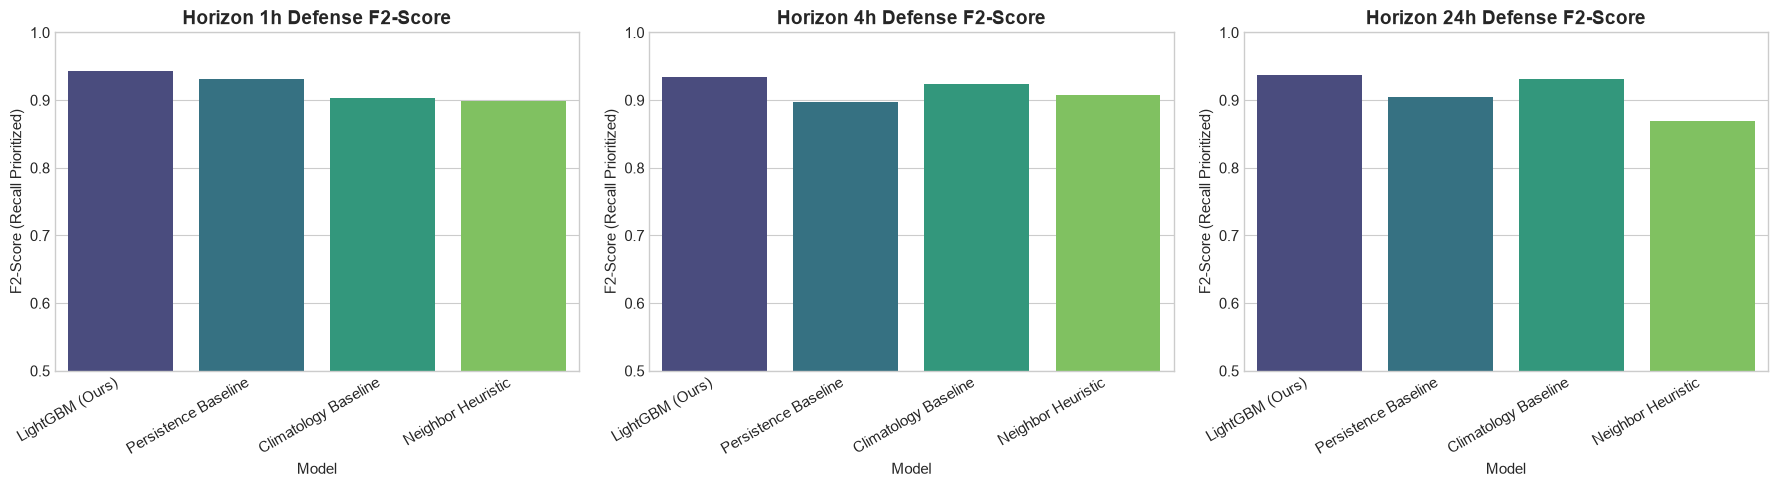

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, h_name in enumerate(['1h', '4h', '24h']):
    sub = df_benchmarks[df_benchmarks['Horizon'] == h_name]
    sns.barplot(data=sub, x='Model', y='F2-Score', ax=axes[i], palette='viridis')
    axes[i].set_title(f'Horizon {h_name} Defense F2-Score', fontsize=14, fontweight='bold')
    axes[i].set_ylim(0.5, 1.0)
    axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=30, ha='right')
    axes[i].set_ylabel('F2-Score (Recall Prioritized)')

plt.tight_layout()
plt.savefig('benchmark_horizons_f2.png', dpi=300)
plt.show()


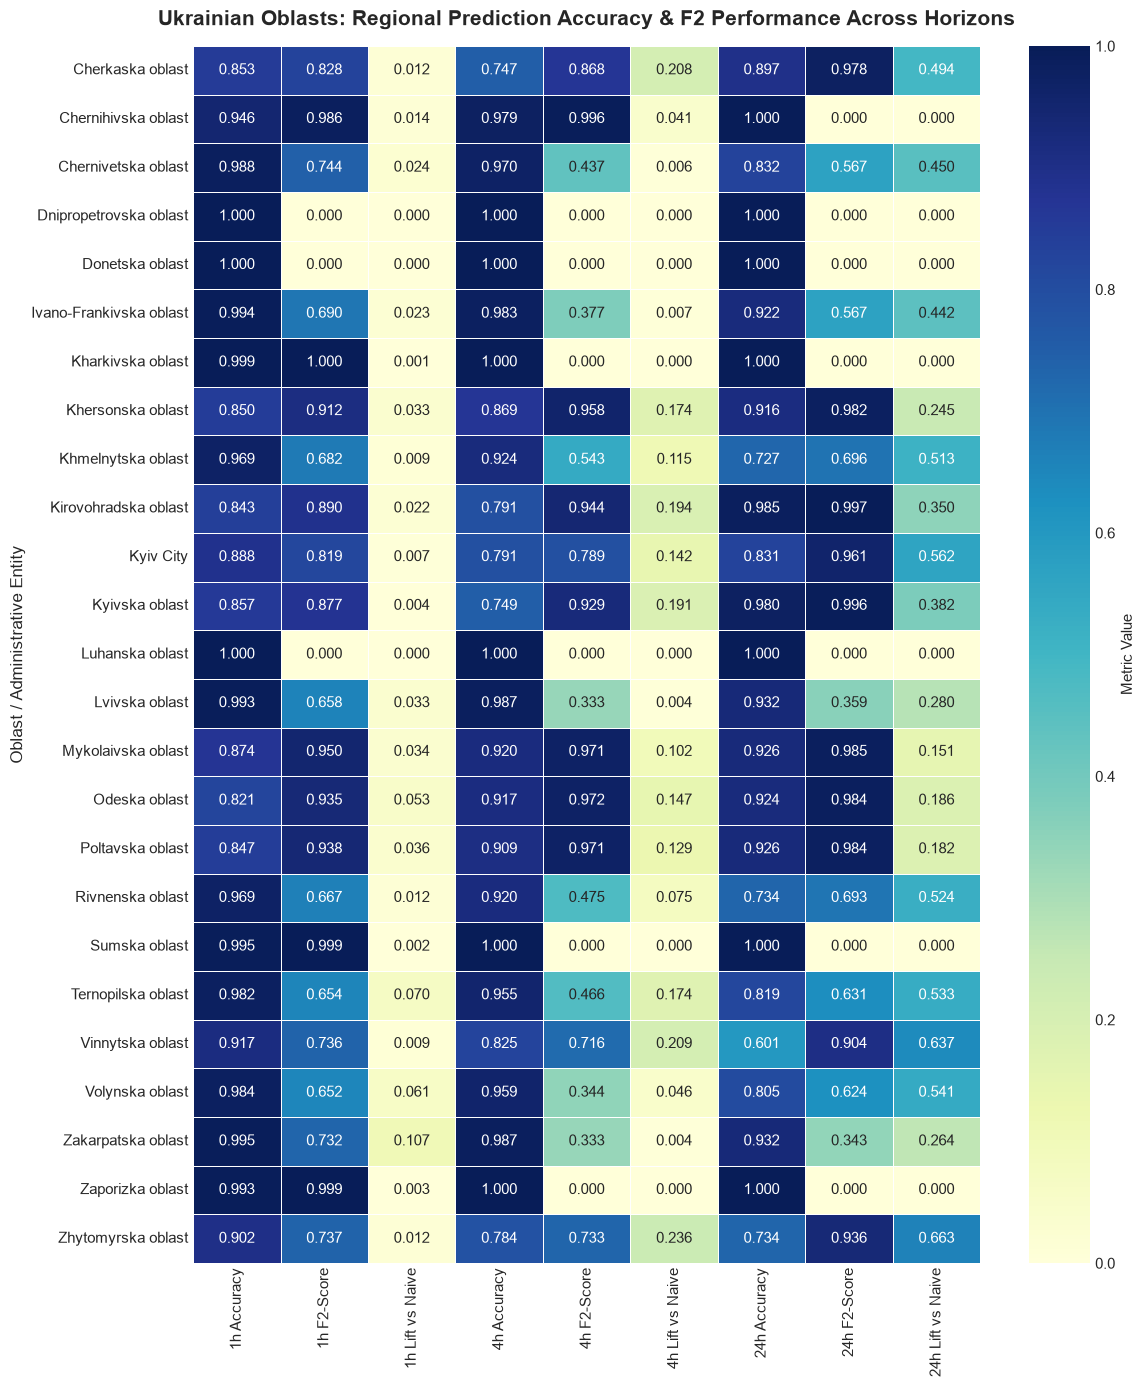

In [9]:
# Combine regional metrics across horizons for a unified heatmap
heat_data = pd.DataFrame(index=REGIONS)
for h_name in ['1h', '4h', '24h']:
    rdf = regional_dfs[h_name].set_index('region')
    heat_data[f'{h_name} Accuracy'] = rdf['model_accuracy']
    heat_data[f'{h_name} F2-Score'] = rdf['model_f2_score']
    heat_data[f'{h_name} Lift vs Naive'] = rdf['f2_lift']

plt.figure(figsize=(12, 14))
sns.heatmap(heat_data, annot=True, fmt='.3f', cmap='YlGnBu', cbar_kws={'label': 'Metric Value'}, linewidths=0.5)
plt.title('Ukrainian Oblasts: Regional Prediction Accuracy & F2 Performance Across Horizons', fontsize=15, fontweight='bold', pad=15)
plt.ylabel('Oblast / Administrative Entity', fontsize=12)
plt.tight_layout()
plt.savefig('regional_performance_heatmap.png', dpi=300)
plt.show()


In [10]:
# Centroids of Ukrainian Oblasts
COORDINATES = {
    'Cherkaska oblast': [49.4444, 32.0598],
    'Chernihivska oblast': [51.4982, 31.2893],
    'Chernivetska oblast': [48.2917, 25.9352],
    'Dnipropetrovska oblast': [48.4647, 35.0462],
    'Donetska oblast': [48.0159, 37.8028],
    'Ivano-Frankivska oblast': [48.9226, 24.7111],
    'Kharkivska oblast': [49.9935, 36.2304],
    'Khersonska oblast': [46.6354, 32.6169],
    'Khmelnytska oblast': [49.4230, 26.9871],
    'Kirovohradska oblast': [48.5079, 32.2623],
    'Kyiv City': [50.4501, 30.5234],
    'Kyivska oblast': [50.2547, 30.2403],
    'Luhanska oblast': [48.5740, 39.3078],
    'Lvivska oblast': [49.8397, 24.0297],
    'Mykolaivska oblast': [46.9750, 31.9946],
    'Odeska oblast': [46.4825, 30.7233],
    'Poltavska oblast': [49.5883, 34.5514],
    'Rivnenska oblast': [50.6199, 26.2516],
    'Sumska oblast': [50.9077, 34.7981],
    'Ternopilska oblast': [49.5535, 25.5948],
    'Vinnytska oblast': [49.2331, 28.4682],
    'Volynska oblast': [50.7472, 25.3254],
    'Zakarpatska oblast': [48.6208, 22.2879],
    'Zaporizka oblast': [47.8388, 35.1396],
    'Zhytomyrska oblast': [50.2547, 28.6587]
}

m = folium.Map(location=[48.3794, 31.1656], zoom_start=6, tiles='CartoDB positron')

rdf_1h = regional_dfs['1h'].set_index('region')

for reg, coord in COORDINATES.items():
    if reg in rdf_1h.index:
        f2 = rdf_1h.loc[reg, 'model_f2_score']
        acc = rdf_1h.loc[reg, 'model_accuracy']
        lift = rdf_1h.loc[reg, 'f2_lift']
        
        # Color coding: Green if high performance, Yellow/Orange if moderate
        color = '#2ecc71' if f2 >= 0.90 else ('#3498db' if f2 >= 0.80 else '#e67e22')
        
        popup_html = f"""
        <b>{reg}</b><br>
        1h Accuracy: {acc:.1%}<br>
        1h F2-Score: {f2:.3f}<br>
        Lift vs Naive: +{lift:.3f}
        """
        
        folium.CircleMarker(
            location=coord,
            radius=12 + (f2 * 8),
            popup=folium.Popup(popup_html, max_width=250),
            tooltip=f"{reg}: {f2:.3f} F2",
            color=color,
            fill=True,
            fill_color=color,
            fill_opacity=0.75
        ).add_to(m)

m.save('regional_accuracy_dashboard.html')
print("Interactive Map saved to regional_accuracy_dashboard.html")
m


c:\Users\yablo\OneDrive\Desktop\CodeStudio\RaidForcasting\.venv\Lib\site-packages\folium\raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


Interactive Map saved to regional_accuracy_dashboard.html
